## Visualizing the embeddings in 2D

We will use t-SNE to reduce the dimensionality of the embeddings from 1536 to 2. Once the embeddings are reduced to two dimensions, we can plot them in a 2D scatter plot. The dataset is created in the [Get_embeddings_from_dataset Notebook](Get_embeddings_from_dataset.ipynb).

https://github.com/openai/openai-cookbook/blob/main/examples/Visualizing_embeddings_in_2D.ipynb


### 1. Reduce dimensionality

We reduce the dimensionality to 2 dimensions using t-SNE decomposition.

In [4]:
import pandas as pd
from sklearn.manifold import TSNE
import numpy as np
from ast import literal_eval

# CSV 파일 경로 지정 (임베딩이 포함된 음식 리뷰 데이터)
datafile_path = "data/fine_food_reviews_with_embeddings_1k.csv"

# CSV 파일을 데이터프레임으로 로드
df = pd.read_csv(datafile_path)

# embedding 컬럼의 문자열을 실제 리스트로 변환 후 2D numpy 배열로 변환
# literal_eval: "[-0.1, 0.2, ...]" 형태의 문자열 → 파이썬 리스트로 변환
matrix = np.array(df.embedding.apply(literal_eval).to_list())

# t-SNE 모델 생성 및 고차원 임베딩을 2차원으로 축소
tsne = TSNE(
    n_components=2,      # 2차원으로 축소
    perplexity=15,       # 각 점의 주변 이웃 수 (보통 5~50 사이)
    random_state=42,     # 재현 가능한 결과를 위한 랜덤 시드
    init='random',       # 초기 임베딩 방식: 랜덤 초기화
    learning_rate=200    # 학습률: 최적화 속도 조절
)

# 행렬에 t-SNE 적용 → 2D 좌표 배열 반환
vis_dims = tsne.fit_transform(matrix)

# 결과 shape 확인 (1000, 2) → 1000개 리뷰 × 2차원 좌표
vis_dims.shape

(1000, 2)

### 2. Plotting the embeddings

We colour each review by its star rating, ranging from red to green.

We can observe a decent data separation even in the reduced 2 dimensions.

Text(0.5, 1.0, 'Amazon ratings visualized in language using t-SNE')

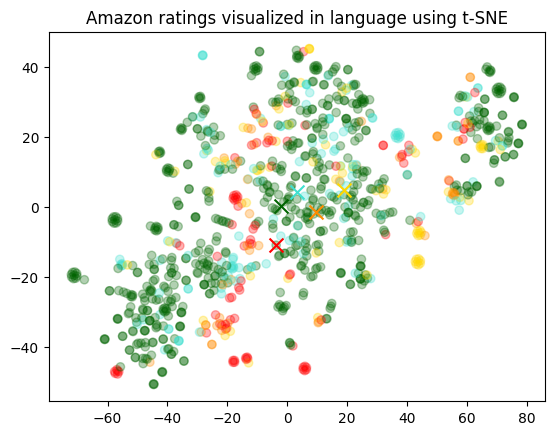

In [5]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

# 점수 1~5점에 대응하는 5가지 색상 정의
colors = ["red", "darkorange", "gold", "turquoise", "darkgreen"]

# t-SNE 결과(vis_dims)에서 x, y 좌표를 각각 분리
x = [x for x, y in vis_dims]
y = [y for x, y in vis_dims]

# 점수(Score)를 0~4 인덱스로 변환 (1~5점 → 0~4)
color_indices = df.Score.values - 1

# 5가지 색상으로 구성된 커스텀 컬러맵 생성
colormap = matplotlib.colors.ListedColormap(colors)

# 모든 리뷰를 산점도로 표시 (alpha=0.3으로 투명하게)
plt.scatter(x, y, c=color_indices, cmap=colormap, alpha=0.3)

# 각 점수별 평균 좌표에 'X' 마커로 중심점 표시
for score in [0, 1, 2, 3, 4]:
    # 해당 점수의 x, y 평균값 계산
    avg_x = np.array(x)[df.Score-1 == score].mean()
    avg_y = np.array(y)[df.Score-1 == score].mean()
    color = colors[score]
    # 'X' 마커로 각 점수 그룹의 중심점 표시 (s=100: 마커 크기)
    plt.scatter(avg_x, avg_y, marker='x', color=color, s=100)

# 차트 제목 설정
plt.title("Amazon ratings visualized in language using t-SNE")